# 07 · Better optimization strategies (model F)

*Level: advanced. Guide Section 11. Code: `bo_advanced.py`.*

Four upgrades of plain Bayesian optimization:
1. a **trust region**: search near the best point, with a box that grows and shrinks;
2. a **learned constraint**: learn where packets fail;
3. **multi-fidelity**: use cheap trace-only packets;
4. **several objectives**: the Pareto front of read noise against dark charge.

All four use the **decomposed surrogate**: one GP for log σe and one for log λ, combined into J. Each part is a simpler function than their
sum.

In [1]:
from tutorial_utils import *

from scipy.stats import norm
from ml import bo_advanced
ei = lambda mu, s, best: (best - mu) * norm.cdf((best - mu) / s) + s * norm.pdf((best - mu) / s)

## 1. A trust region, by hand (2 settings)

* Candidates are drawn only in a box of side $L$ (a fraction of each range) around the best point.
* $L$ doubles after 3 improvements in a row and halves after 5 failures.
* The search stays local and moves with the best point, like a CCD whose voltages change in bounded steps.

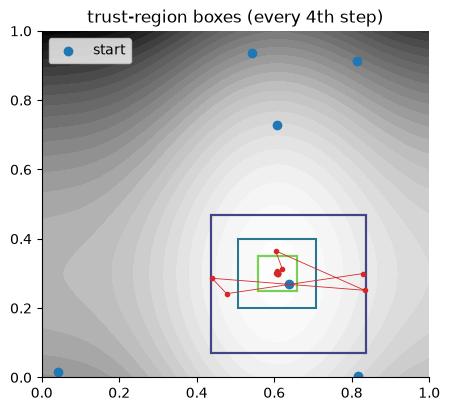

best J -0.140


In [2]:
f2 = lambda p: (p[..., 0] - 0.7) ** 2 + 2 * (p[..., 1] - 0.3) ** 2 + 0.15 * np.sin(8 * p[..., 0])
rng = np.random.default_rng(0)
P = rng.random((6, 2)); J = f2(P); L, succ, fail, boxes = 0.4, 0, 0, []
for step in range(20):
    best = P[np.argmin(J)]
    lo, hi = np.clip(best - L / 2, 0, 1), np.clip(best + L / 2, 0, 1); boxes.append((lo, hi))
    cand = lo + (hi - lo) * rng.random((2000, 2))
    m, s = models.GP().fit(P, J[:, None]).predict(cand)
    nxt = cand[np.argmax(ei(m[:, 0], np.maximum(s[:, 0], 1e-9), J.min()))]
    improved = f2(nxt) < J.min() - 1e-3
    P, J = np.vstack([P, nxt]), np.append(J, f2(nxt))
    succ, fail = (succ + 1, 0) if improved else (0, fail + 1)
    if succ >= 3: L, succ = min(2 * L, 1), 0
    if fail >= 5: L, fail = L / 2, 0
g = np.linspace(0, 1, 100); G = np.stack(np.meshgrid(g, g), -1)
plt.figure(figsize=(5, 4.5)); plt.contourf(g, g, f2(G), 30, cmap="Greys")
for k, (lo, hi) in enumerate(boxes[::4]):
    plt.gca().add_patch(plt.Rectangle(lo, *(hi - lo), fill=False, color=plt.cm.viridis(k / 5), lw=1.5))
plt.plot(*P[6:].T, "C3.-", lw=0.6); plt.scatter(*P[:6].T, color="C0", label="start"); plt.legend(); plt.title("trust-region boxes (every 4th step)")
plt.show(); print(f"best J {J.min():.3f}")

## 2. A constraint that must be learned

If the safe region were unknown, packets outside it would fail. A GP regression on outcomes $\pm1$ gives
$P(\text{feasible}) = \Phi(\mu_c/s_c)$, and the acquisition becomes $\mathrm{EI} \times P(\text{feasible})$.

We **know** the CCD's rules (`ccd_limits.py`), so the project uses the known constraint. This is for limits that cannot be written down.

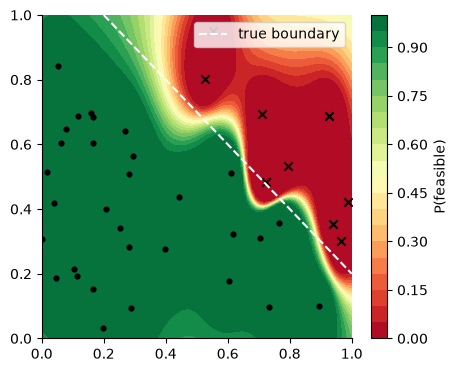

In [3]:
Pc = rng.random((40, 2)); ok = (Pc[:, 0] + Pc[:, 1] < 1.2)
gpc = models.GP().fit(Pc, np.where(ok, 1.0, -1.0)[:, None])
mc, sc = gpc.predict(G.reshape(-1, 2)); pf = norm.cdf(mc[:, 0] / np.maximum(sc[:, 0], 1e-9)).reshape(100, 100)
plt.figure(figsize=(5, 4.2)); plt.contourf(g, g, pf, 20, cmap="RdYlGn"); plt.colorbar(label="P(feasible)")
plt.scatter(*Pc[ok].T, c="k", marker="o", s=12); plt.scatter(*Pc[~ok].T, c="k", marker="x"); plt.plot([0.2, 1], [1, 0.2], "w--", label="true boundary")
plt.legend(); plt.show()

## 3. Cheap trace-only packets (multi-fidelity)

A trace-only packet takes ~1 minute and measures the noise in ADU, but not the gain or λ. The classic way to combine a cheap and an
expensive measurement is **co-kriging**:

$$f_\text{expensive}(\theta) = \rho\,f_\text{cheap}(\theta) + \delta(\theta),$$

with $\rho$ a learned factor and $\delta$ a GP correction. Our version uses model A (notebook 08): trace noise minus the predicted log gain is
an observation of $\log\sigma_e$. It pays off only if the trace predicts the image well. That is exactly what level 1 tests.

## 4. Several objectives: the Pareto front and the hypervolume

* Settings **dominate** others if they are at least as good in both objectives and better in one.
* The non-dominated ones form the **Pareto front**: the best available trade-offs.
* The **hypervolume** (the area they dominate, up to a reference point) scores a front.
* **ParEGO** draws a random weight $w$ for $J_w = \log\sigma_e + w\log\lambda$ at each step, so the packets spread along the front.

11 of 40 points are on the front; hypervolume = 0.785


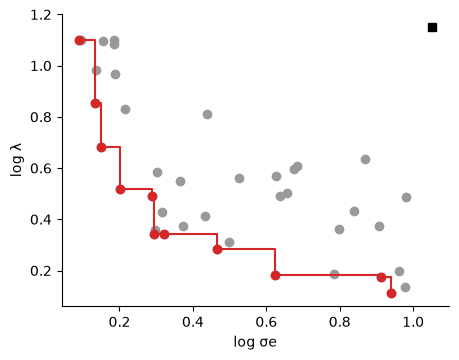

In [4]:
pts = np.column_stack([rng.uniform(0.05, 1, 40), np.zeros(40)]); pts[:, 1] = np.minimum(0.1 / pts[:, 0] + rng.uniform(0, 0.6, 40), 1.1)
def pareto(p):
    keep = [i for i in range(len(p)) if not np.any(np.all(p <= p[i], 1) & np.any(p < p[i], 1))]
    return p[sorted(keep, key=lambda i: p[i, 0])]
front = pareto(pts); ref = np.array([1.05, 1.15])
print(f"{len(front)} of {len(pts)} points are on the front; hypervolume = {bo_advanced.hypervolume_2d(pts, ref):.3f}")
plt.figure(figsize=(5, 3.8)); plt.scatter(*pts.T, color="0.6"); plt.step(*front.T, where="post", color="C3"); plt.scatter(*front.T, color="C3")
plt.plot(*ref, "ks"); plt.xlabel("log σe"); plt.ylabel("log λ"); plt.show()

## 5. On the toy CCD: global EI against the trust region

`bo_advanced.run` simulates whole campaigns with the decomposed surrogate. The score is the *true* objective at the best point found.

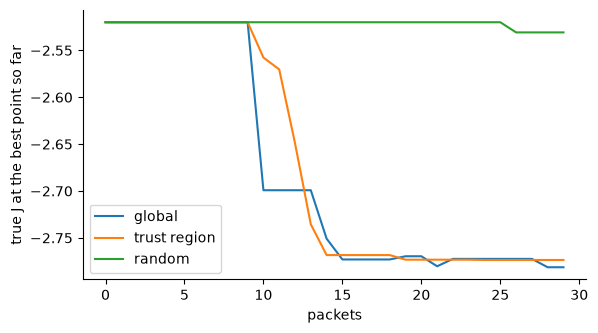

In [5]:
plt.figure(figsize=(6.5, 3.5))
for strategy in ("global", "trust region", "random"):
    res = bo_advanced.run(strategy, seed=0, n_total=30, n_initial=10)
    plt.plot(res["best_true"], label=strategy)
plt.xlabel("packets"); plt.ylabel("true J at the best point so far"); plt.legend(); plt.show()

One campaign is noisy: which strategy is ahead changes from seed to seed. Over several campaigns in the project's tests
(`docs/ml_results/advanced_bo.json`), the trust region found the best settings.

## When to use which

| Strategy | Use when |
|---|---|
| trust region | many settings; bounded steps (best in our tests) |
| learned constraint | limits unknown (ours are known) |
| multi-fidelity | the trace predicts the image well and trace packets are much cheaper |
| ParEGO | to see the σe–λ trade-off before fixing $w$ |

Next: **08 · Model A, physics-structured outputs.**